# 01 · Confounding and regression adjustment

**Question:** what is the average effect of a binary treatment `D` on an outcome `Y`
when covariates `X` influence both?

```
  X ──► D ──► Y
  └──────────►┘
```

`X` is a **confounder**: it opens a back-door path `D ◄─ X ─► Y`. Comparing treated and
untreated means mixes the effect of `D` with the effect of `X`. Conditioning on `X`
blocks that path.

**You will implement:** OLS with classical and HC1 (robust) standard errors, and two
flavours of regression adjustment (single regression and per-arm "g-computation").

**Library check:** `statsmodels.OLS`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

import causalsim as cs
from causalsim.plotting import use_style, truth_line

use_style()

## 1. Simulate
True ATE = 2. Treatment is more likely when `X` is high, and high `X` also raises `Y`.

In [2]:
sim = cs.confounded_binary(n=5_000, ate=2.0, confounding=1.0, seed=0)
df = sim.data
print(sim)
df.head()

SimResult(n=5000, cols=['X1', 'X2', 'X3', 'D', 'Y'], truth={ate=2, att=2, cate=array(5000,), propensity=array(5000,)})


,X1,X2,X3,D,Y
0,0.125730,-0.132105,0.640423,1,1.700741
1,0.104900,-0.535669,0.361595,0,-0.092248
2,1.304000,0.947081,-0.703735,1,3.492384
3,-1.265421,-0.623274,0.041326,0,-1.812707
4,-2.325031,-0.218792,-1.245911,0,-4.866409


In [3]:
naive = df.loc[df.D == 1, "Y"].mean() - df.loc[df.D == 0, "Y"].mean()
print(f"naive difference in means: {naive:.3f}   (truth {sim.truth['ate']})")

naive difference in means: 3.828   (truth 2.0)


The naive estimate is badly biased upward: treated units would have had higher `Y` anyway.

## 2. From scratch: OLS

$\hat\beta = (X^\top X)^{-1} X^\top y$, classical covariance $\hat\sigma^2 (X^\top X)^{-1}$ with
$\hat\sigma^2 = \text{RSS}/(n-k)$, and HC1 robust covariance
$\frac{n}{n-k}(X^\top X)^{-1} X^\top \text{diag}(\hat e^2) X (X^\top X)^{-1}$.

In [4]:
def ols(X: np.ndarray, y: np.ndarray, robust: bool = False):
    """Return (beta, standard_errors). X must already include an intercept column."""
    n, k = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    if robust:  # HC1
        meat = (X * resid[:, None] ** 2).T @ X
        cov = XtX_inv @ meat @ XtX_inv * n / (n - k)
    else:
        sigma2 = resid @ resid / (n - k)
        cov = sigma2 * XtX_inv
    return beta, np.sqrt(np.diag(cov))


def add_const(*cols):
    return np.column_stack([np.ones(len(cols[0])), *cols])

### 2a. Regression adjustment, single model: `Y ~ D + X`
The coefficient on `D` is the ATE **if** the outcome is linear in `X` and the effect is constant.

In [5]:
X_cols = ["X1", "X2", "X3"]
Xmat = add_const(df.D.to_numpy(), df[X_cols].to_numpy())
beta, se = ols(Xmat, df.Y.to_numpy())
beta_r, se_r = ols(Xmat, df.Y.to_numpy(), robust=True)
ra_single = beta[1]
print(f"regression adjustment: {ra_single:.3f} ± {1.96*se[1]:.3f} (classical), ± {1.96*se_r[1]:.3f} (HC1)")

regression adjustment: 1.982 ± 0.063 (classical), ± 0.063 (HC1)


### 2b. g-computation (per-arm outcome models)
Fit $\mu_1(x)=E[Y\mid D=1,X=x]$ and $\mu_0(x)$ separately, then average the predicted
difference over **everyone**: $\widehat{ATE} = \frac1n\sum_i \hat\mu_1(x_i)-\hat\mu_0(x_i)$.
This allows the effect to vary with `X`, which the single regression does not.

In [6]:
def g_computation(df, x_cols, d="D", y="Y"):
    X = add_const(df[x_cols].to_numpy())
    mu = {}
    for arm in (0, 1):
        m = df[d].to_numpy() == arm
        b, _ = ols(X[m], df[y].to_numpy()[m])
        mu[arm] = X @ b
    return np.mean(mu[1] - mu[0])

ra_gcomp = g_computation(df, X_cols)
print(f"g-computation: {ra_gcomp:.3f}")

g-computation: 1.982


## 3. Library check: statsmodels
Coefficients and both kinds of standard errors should match to numerical precision.

In [7]:
sm_fit = sm.OLS(df.Y, sm.add_constant(df[["D"] + X_cols])).fit()
sm_fit_r = sm.OLS(df.Y, sm.add_constant(df[["D"] + X_cols])).fit(cov_type="HC1")

np.testing.assert_allclose(beta, sm_fit.params.to_numpy(), rtol=1e-10)
np.testing.assert_allclose(se, sm_fit.bse.to_numpy(), rtol=1e-10)
np.testing.assert_allclose(se_r, sm_fit_r.bse.to_numpy(), rtol=1e-10)
print("✓ from-scratch OLS matches statsmodels (coefficients, classical SE, HC1 SE)")

assert abs(ra_single - sim.truth["ate"]) < 0.1
assert abs(ra_gcomp - sim.truth["ate"]) < 0.1
print("✓ both regression-adjustment estimates are within 0.1 of the true ATE")

✓ from-scratch OLS matches statsmodels (coefficients, classical SE, HC1 SE)
✓ both regression-adjustment estimates are within 0.1 of the true ATE


## 4. Monte Carlo: bias vs. noise
One dataset can be lucky. Repeat 300 times and look at the sampling distributions.

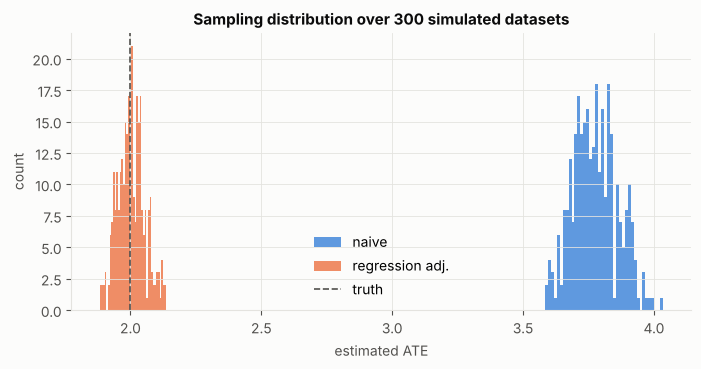

,naive,regression adj.
mean,3.775,2.003
std,0.086,0.052


In [8]:
rows = []
for s in range(300):
    d = cs.confounded_binary(n=2_000, ate=2.0, seed=1_000 + s).data
    nv = d.loc[d.D == 1, "Y"].mean() - d.loc[d.D == 0, "Y"].mean()
    b, _ = ols(add_const(d.D.to_numpy(), d[X_cols].to_numpy()), d.Y.to_numpy())
    rows.append({"naive": nv, "regression adj.": b[1]})
mc = pd.DataFrame(rows)

fig, ax = plt.subplots()
for col in mc:
    ax.hist(mc[col], bins=40, alpha=0.75, label=col)
truth_line(ax, 2.0)
ax.set(title="Sampling distribution over 300 simulated datasets", xlabel="estimated ATE", ylabel="count")
ax.legend()
plt.show()
mc.describe().loc[["mean", "std"]].round(3)

## 5. Break it

Each scenario violates one assumption. Predict the result **before** running the cell.

| scenario | what is violated |
|---|---|
| hidden confounder | conditional ignorability: `U` affects `D` and `Y` but isn't in `X` |
| non-linear outcome | the linear outcome model is misspecified |
| heterogeneous effect | constant-effect assumption of the single regression |

In [9]:
scenarios = {
    "baseline": dict(),
    "hidden confounder": dict(hidden_confounding=1.0),
    "non-linear outcome": dict(nonlinear_outcome=True),
    "heterogeneous effect": dict(effect_heterogeneity=1.5),
    "non-linear + heterogeneous": dict(nonlinear_outcome=True, effect_heterogeneity=1.5),
}
out = []
for name, kw in scenarios.items():
    s = cs.confounded_binary(n=20_000, ate=2.0, seed=7, **kw)
    d = s.data
    b, _ = ols(add_const(d.D.to_numpy(), d[X_cols].to_numpy()), d.Y.to_numpy())
    out.append({
        "scenario": name,
        "truth ATE": s.truth["ate"],
        "naive": d.loc[d.D == 1, "Y"].mean() - d.loc[d.D == 0, "Y"].mean(),
        "single regression": b[1],
        "g-computation": g_computation(d, X_cols),
    })
pd.DataFrame(out).set_index("scenario").round(3)

,truth ATE,naive,single regression,g-computation
scenario,,,,
baseline,2.0,3.752,1.998,1.998
hidden confounder,2.0,4.955,3.699,3.699
non-linear outcome,2.0,4.275,2.152,2.145
heterogeneous effect,2.0,4.304,1.995,1.984
non-linear + heterogeneous,2.0,4.827,2.149,2.130


**What to notice**

- *Hidden confounder:* every estimator is biased. No amount of modelling of observed `X` fixes a missing confounder.
- *Heterogeneous effect:* in general the single regression does **not** target the ATE. It returns an average
  of conditional effects weighted by $e(x)(1-e(x))$, the conditional variance of treatment. Here it lands near 2
  anyway, because those weights happen to be symmetric in `X1`. g-computation targets the ATE by construction.
  (Exercise 4 makes the difference visible.)
- *Non-linear outcome:* both linear approaches can drift. Notebooks 02-03 show estimators that lean on the
  propensity model instead, and notebook 05 replaces the linear models with machine learning.

**Exercises**
1. Set `confounding=0.0` (a randomized experiment). Is adjustment still useful? Compare the standard errors.
2. Add a *collider*: create `C = D + Y + noise` and include it in `X`. What happens to the estimate?
3. Rewrite `ols` using `np.linalg.lstsq` or a QR decomposition, and explain why `inv(X.T @ X)` is numerically fragile.
4. Make the single regression miss the ATE: simulate with `effect_heterogeneity=1.5` and a propensity that depends on
   `X1` asymmetrically (e.g. edit the simulator so `logit = 2*X1 + 1`). Compare it with g-computation.